# p03_silver_model: the procurement data model (`proc_silver`)

Turns the two raw feeds into a small, keyed, documented model. Every table states its **grain** (what one row is) and its **primary key**; relationships are declared as Unity Catalog foreign keys and then *counted*, because Databricks does not enforce them.

| Table | Grain (one row per ...) | Primary key | Built from |
|---|---|---|---|
| `dim_procurement_category` | procurement category (Works, Goods, ...) | `category_code` | reference data |
| `dim_procurement_method` | procurement method | `method_name` | both feeds + reference data |
| `dim_country` | country or Bank regional programme | `country_code` | both feeds + indicators |
| `dim_project` | World Bank project seen in either feed | `project_id` | both feeds + outcome project tables |
| `contracts` | signed WB contract | `contract_id` | awards |
| `suppliers` | supplier registration id (`supplier_id`) | `supplier_id` | awards + award notices |
| `contract_suppliers` | contract x supplier (joint-venture members are separate rows) | `contract_id, supplier_id` | awards |
| `notices` | procurement notice dated 2018-01-01 or later | `notice_id` | notices |
| `notice_bidders` | award notice x firm named in it (awarded / evaluated / rejected) | `notice_id, supplier_id` | award notice HTML |

Entity resolution (`p04`) adds `supplier_entities`; notice-to-contract linking (`p05`) adds `notice_contract_links`.

## Entity-relationship diagram

%md-sandbox
<p><b>Core contract model</b></p>
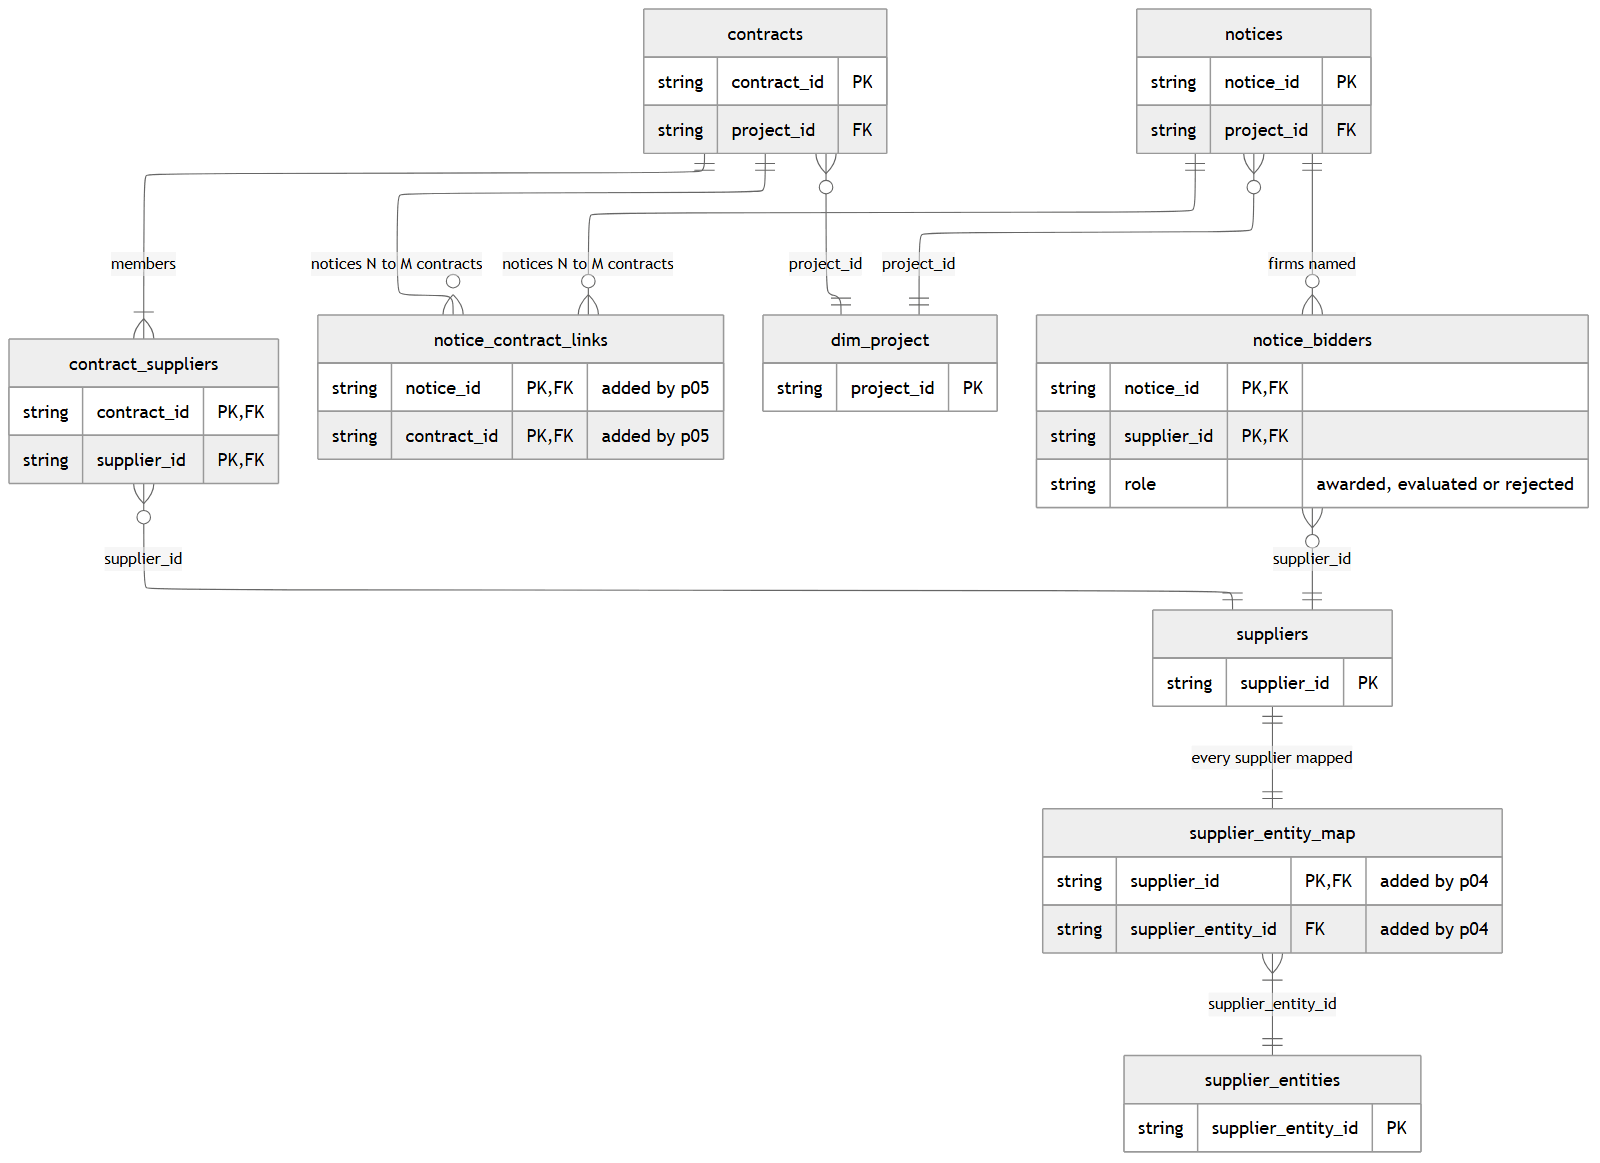

<p><b>Lookups: dimension tables and the FKs that point to them</b></p>
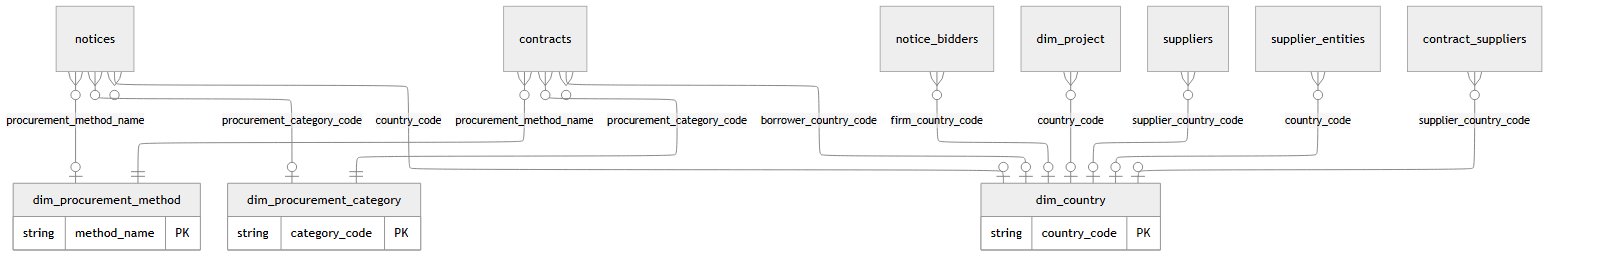


notice_bidders keeps the strongest role per firm per notice (awarded > evaluated > rejected; see the dedup in section 5, `notices` and `notice_bidders`); per-lot outcomes would need the lot in the key.

Every `dim_project` row is referenced by at least one notice or contract. Reused from the outcome project by join, not copied: `silver.country_year` (WGI + macro) on (`country_code` = `country_iso2`, year); `silver.projects`, `gold.active_project_scores` and `silver.rag_chunks` on `project_id`.

## Key design decisions

| Decision | Rationale | Evidence |
|---|---|---|
| `contracts.contract_amount_usd` holds the amount once per contract (the maximum of the rows), with `amount_spread_ratio` kept as a quality flag | `supplier_contract_amount_usd` is the contract value repeated per joint-venture member; summing the raw column would double-count every joint venture | In 7,083 of the 8,864 multi-supplier contracts every row carries the identical amount; in the other 1,781 the values differ by a fixed ratio, almost always exactly 1.0303 or 1.0003 (a conversion artefact, not a split); contract 1543858 lists AIRES INGEGNERIA and ALL INGEGNERIA, both at US$161,538.89 |
| Project, method, category, dates and reference stored once in `contracts`; `contract_suppliers` keeps only what varies by member | These attributes are contract-level | For all 282,890 contracts each of these columns has exactly one value (re-checked in the quality table) |
| One crosswalk (`proc_intel.countries`) maps every code and name to ISO alpha-2, or to the Bank's regional code | Without it, five borrowers would silently lose their governance indicators | The feed uses Bank codes: DR Congo `ZR`, Serbia `YF`, Yemen `RY`, Timor-Leste `TP`, West Bank and Gaza `GZ` (ISO `CD`, `RS`, `YE`, `TL`, `PS`); Côte d'Ivoire and Somalia rows have no code (4,972 and 2,837 rows); regional codes such as `3W`; notices use names with their own spellings ("Turkey", "Türkiye", "Vietnam", "Somalia") |
| `suppliers` has one row per `supplier_id` with a flag for anonymised individuals; grouping ids into firms is done in `p04`; the award row without an id gets a surrogate id `NOID-<hash>` | `supplier_id` is a registration id, not a firm identity | Individual consultants are anonymised ("INDIVIDUAL CONSULTANT", 16-character hashed id, 65,121 rows); 6,648 names occur under more than one id |
| Firm ids, names, countries and roles parsed from award notices into `notice_bidders`; beneficial-ownership tables never read; bidders that never won a contract still get a `suppliers` row | Losing bidders are a competition signal; ownership tables name private persons; the foreign key must hold | Award-notice HTML lists awarded, evaluated and rejected firms as "NAME (supplier id)", plus the award notification date and contract duration; some notices carry beneficial-ownership tables |
| Primary and foreign keys declared, and duplicates and orphans counted in the closing quality table | Unity Catalog keys are informational, not enforced | Nothing stops a duplicate or an orphan from being written |

Full reasoning: docs/decision_log.md

## Setup

**What:** installs the two small libraries the shared package needs, loads `proc_common`, and imports the pure functions used as Spark UDFs.

**Why:** country, method, category and reference rules live in `src/proc_intel` with unit tests; here they are wrapped as UDFs so the notebook applies exactly the tested code.

In [ ]:
%pip install -q rapidfuzz unidecode

Note: you may need to restart the kernel using %restart_python or dbutils.library.restartPython() to use updated packages.


In [ ]:
dbutils.library.restartPython()

In [ ]:
%run ./proc_common

In [ ]:
import json

from pyspark.sql import Window
from pyspark.sql.types import (ArrayType, DateType, IntegerType, StringType, StructField,
                               StructType)

from proc_intel.countries import NAME_TO_ISO2, REGIONAL_CODES, to_iso2
from proc_intel.notices import parse_award_notice
from proc_intel.procurement import CATEGORIES, category_code, clean_method_name, method_competition
from proc_intel.references import normalise_reference, step_activity_id

# Each UDF wraps a tested pure function from src/proc_intel and runs once per row in Python.
to_iso2_udf = as_udf(to_iso2, StringType())
category_udf = as_udf(category_code, StringType())
method_udf = as_udf(clean_method_name, StringType())
competition_udf = as_udf(method_competition, StringType())
ref_norm_udf = as_udf(normalise_reference, StringType())
step_id_udf = as_udf(step_activity_id, StringType())
# parse_award_notice returns a dict; this schema tells Spark its shape: two scalars plus a list of firm structs.
award_schema = StructType([
    StructField("award_notification_date", DateType()),
    StructField("contract_duration_days", IntegerType()),
    StructField("firms", ArrayType(StructType([StructField(c, StringType())
                                               for c in ("supplier_id", "name", "country_name", "role")]))),
])
award_udf = as_udf(parse_award_notice, award_schema)

# soft-deleted bronze rows stay for the audit trail but must not reach the model
awards = spark.table(f"{BRONZE}.contract_awards").filter("_removed_at_source IS NULL")
raw_notices = spark.table(f"{BRONZE}.procurement_notices")
INDIVIDUAL_ID = "^[0-9a-f]{16}$"     # anonymised individual consultants

# foreign keys pointing at a parent table block overwriting it, so drop them all first and redeclare them in section 9
dropped_fks = drop_foreign_keys(SILVER)
print("foreign keys dropped before rebuild:", dropped_fks)

foreign keys dropped before rebuild: 22


## 1. `dim_procurement_category`

**What:** the four categories with the code used by notices (`CW`, `GO`, `CS`, `NC`) and the name used by awards.

**Why:** a shared code lets contracts and notices be compared and joined by category.

In [ ]:
categories = spark.createDataFrame([(k, v) for k, v in CATEGORIES.items()], "category_code string, category_name string")
n_categories = publish_table(
    categories, f"{SILVER}.dim_procurement_category",
    "Procurement categories. Grain: one row per category. Code as in notices (CW/GO/CS/NC), name as in awards.",
    {"category_code": "PK. CW works, GO goods, CS consultant services, NC non-consulting services",
     "category_name": "Name used by the contract awards feed"},
    primary_key=["category_code"])
print("categories:", n_categories)

categories: 4


## 2. `dim_procurement_method`

**What:** every method name found in either feed (repeated spaces collapsed), its short code from the notices feed, the analyst grouping `competition` (open / limited / direct / other, from `proc_intel.procurement`), and how often each feed uses it.

**Why:** both feeds use the same names, so the cleaned name is the conformed key. `competition` matters downstream: only openly competed methods are expected to have a published tender notice, which sets the denominator for tender timelines in `p05`.

In [ ]:
# One row per notice: its cleaned method name and its method code (blank codes become null).
notice_methods = (raw_notices.select(method_udf("procurement_method_name").alias("method_name"),
                                     F.nullif(F.trim("procurement_method_code"), F.lit("")).alias("code"))
                  .filter("method_name IS NOT NULL"))
# a name can appear with more than one code in the notices feed; keep its most frequent code
method_codes = (notice_methods.filter("code IS NOT NULL").groupBy("method_name", "code").count()
                .withColumn("rn", F.row_number().over(Window.partitionBy("method_name").orderBy(F.desc("count"))))
                .filter("rn = 1").select("method_name", F.col("code").alias("method_code")))
# Grain of methods: one row per cleaned method name, with how many award rows and notices use it.
methods = (awards.select(method_udf("procurement_method").alias("method_name"))
           .groupBy("method_name").agg(F.count("*").alias("n_award_rows"))
           # full join: some methods occur in only one of the two feeds
           .join(notice_methods.groupBy("method_name").agg(F.count("*").alias("n_notices")), "method_name", "full")
           .filter("method_name IS NOT NULL")  # clean_method_name returns None for blank names
           .join(method_codes, "method_name", "left")
           .withColumn("competition", competition_udf("method_name"))
           .fillna(0, ["n_award_rows", "n_notices"])  # a method absent from one feed gets 0 there, not null
           .select("method_name", "method_code", "competition", "n_award_rows", "n_notices"))
n_methods = publish_table(
    methods, f"{SILVER}.dim_procurement_method",
    "Procurement methods (World Bank Procurement Regulations and legacy guidelines). Grain: one row per method name.",
    {"method_name": "PK. Method name as used by both feeds, repeated spaces collapsed",
     "method_code": "Short code from the notices feed (most frequent code for the name)",
     "competition": "Analyst grouping: open (advertised), limited (quotations/shortlist), direct, other (not a market approach)",
     "n_award_rows": "Rows in bronze contract_awards using this method",
     "n_notices": "Notices in bronze procurement_notices using this method"},
    primary_key=["method_name"])
display(spark.table(f"{SILVER}.dim_procurement_method").orderBy(F.desc("n_award_rows")))

method_name                         | method_code | competition | n_award_rows | n_notices
------------------------------------+-------------+-------------+--------------+----------
Request for Quotations              | RFQ         | limited     | 106532       | 120474   
Individual Consultant Selection     | INDV        | limited     | 65121        | 89351    
Request for Bids                    | RFB         | open        | 56799        | 85839    
Direct Selection                    | CDS         | direct      | 35293        | 38047    
Consultant Qualification Selection  | CQS         | limited     | 16393        | 27740    
Quality And Cost-Based Selection    | QCBS        | open        | 10978        | 28398    
Least Cost Selection                | LCS         | open        | 1584         | 3233     
Quality Based Selection             | QBS         | open        | 558          | 1484     
Community Driven Development        | CDD         | other       | 484          | 574      

## 3. Country lookup (name -> code)

**What:** a lookup from every country spelling in the data to one code: awards borrower and supplier names (codes crosswalked as in Step 3), the World Development Indicators names *for those same codes*, the Bank's regional programme codes, and a short alias list for spellings only the notices use. The assert proves no name points to two codes.

**Why:** the notices feed and the award-notice HTML carry country *names* only. Indicator names are used only for codes already seen in the awards, because the indicators table also holds aggregates ("Latin America & Caribbean", "World") that must not become countries.

In [ ]:
# Every distinct (country_code, name) pair in the awards: borrower and supplier columns stacked, codes crosswalked by to_iso2.
award_names = (awards.select(to_iso2_udf("borrower_country_code", "borrower_country").alias("country_code"),
                             F.col("borrower_country").alias("name"))
               .unionByName(awards.select(to_iso2_udf("supplier_country_code", "supplier_country").alias("country_code"),
                                          F.col("supplier_country").alias("name")))
               .filter("country_code IS NOT NULL AND name IS NOT NULL").distinct())
# only for codes already seen in the awards: the indicators table also holds aggregates ("World", regions) that are not
# countries
# The left_semi join is a filter: it keeps indicator rows whose code is in the awards and adds no columns.
indicator_names = (spark.table(OUTCOME_INDICATORS).filter("country_iso2 <> ''")
                   .groupBy(F.col("country_iso2").alias("country_code"))
                   .agg(F.first("country_name").alias("indicator_name"))
                   .join(award_names.select("country_code").distinct(), "country_code", "left_semi"))
# NAME_TO_ISO2: spellings with no code in the awards or spelled differently in notices. REGIONAL_CODES: Bank programme codes.
alias_names = spark.createDataFrame(list(NAME_TO_ISO2.items()), "name string, country_code string")
regional_names = spark.createDataFrame(list(REGIONAL_CODES.items()), "country_code string, name string")
# One row per (name, country_code) pair from all four sources; cached because it is counted, checked and joined below.
name_to_code = (award_names.unionByName(alias_names)
                .unionByName(indicator_names.select("country_code", F.col("indicator_name").alias("name")))
                .unionByName(regional_names).distinct().cache())
ambiguous = name_to_code.groupBy("name").agg(F.countDistinct("country_code").alias("codes")).filter("codes > 1")
# a spelling that maps to two codes would duplicate rows in every join on this lookup
assert ambiguous.count() == 0, f"country names mapping to several codes: {ambiguous.collect()}"
# _cname is the join column for the name lookups in section 5 (notice country and bidder country).
country_lookup = name_to_code.withColumnRenamed("name", "_cname")
print("country spellings:", name_to_code.count(), "| codes:", name_to_code.select("country_code").distinct().count())

country spellings: 257 | codes: 238


## 4. `contracts`

**What:** one row per `wb_contract_number`: project, borrower country (crosswalked), signing date, method, category, review type, the raw and normalised borrower reference with its STEP activity id, the contract amount counted **once**, the number of supplier rows, and flags for joint ventures and anonymised individual consultants.

**Why:** this is the fact table most analysis starts from. The normalised reference and STEP activity id are the join keys to tender notices in `p05`.

In [ ]:
# first() is safe for the contract-level columns: section 10 checks that none of them varies within a contract
# awards has one row per contract x supplier; the groupBy collapses it to one row per contract.
contracts = (awards.groupBy(F.col("wb_contract_number").alias("contract_id")).agg(
        F.first("project_id").alias("project_id"),
        F.first("borrower_country_code").alias("_bcode"), F.first("borrower_country").alias("borrower_country_name"),
        F.first("contract_signing_date").alias("_signed"), F.first("fiscal_year").alias("fiscal_year"),
        F.first("procurement_method").alias("_method"), F.first("procurement_category").alias("_category"),
        F.first("review_type").alias("review_type"),
        F.first("borrower_contract_reference_number").alias("borrower_reference"),
        F.first("contract_description").alias("contract_description"),
        # max, not sum: the feed repeats the contract value on every joint-venture member row
        F.max("supplier_contract_amount_usd").alias("contract_amount_usd"),
        # spread is usually 1.0; ~1.03 or ~1.0003 is a known conversion artefact, not a split between members
        # nullif turns a minimum of 0 into null, so the ratio is null instead of a division by zero
        (F.max("supplier_contract_amount_usd") / F.nullif(F.min("supplier_contract_amount_usd"), F.lit(0.0)))
            .alias("amount_spread_ratio"),
        F.count("*").alias("n_suppliers"),
        # max of a boolean is True when any supplier row of the contract has an anonymised id
        F.max(F.col("supplier_id").rlike(INDIVIDUAL_ID)).alias("is_individual_consultant"),
        F.max("as_of_date").alias("as_of_date"))
    # the _-prefixed raw columns are converted here: country crosswalk, text date to date, method and category UDFs
    .select("contract_id", "project_id",
            to_iso2_udf("_bcode", "borrower_country_name").alias("borrower_country_code"), "borrower_country_name",
            F.to_date("_signed", "dd-MMM-yyyy").alias("signing_date"), "fiscal_year",
            method_udf("_method").alias("procurement_method_name"),
            category_udf("_category").alias("procurement_category_code"),
            "review_type", "borrower_reference",
            # reference_norm and step_activity_id are the join keys to tender notices in p05
            ref_norm_udf("borrower_reference").alias("reference_norm"),
            step_id_udf("borrower_reference").alias("step_activity_id"),
            "contract_description", "contract_amount_usd", "amount_spread_ratio", "n_suppliers",
            (F.col("n_suppliers") > 1).alias("is_joint_venture"), "is_individual_consultant", "as_of_date"))
n_contracts = publish_table(
    contracts, f"{SILVER}.contracts",
    "Signed World Bank IPF contracts. Grain: one row per wb_contract_number. Amount counted once per contract "
    "(the awards feed repeats it on every joint-venture member row).",
    {"contract_id": "PK. wb_contract_number from the awards feed",
     "project_id": "FK dim_project",
     "borrower_country_code": "FK dim_country. ISO alpha-2 or Bank regional code; null for unnamed regional programmes",
     "borrower_country_name": "Borrower country / programme name as delivered",
     "signing_date": "Contract signing date",
     "fiscal_year": "World Bank fiscal year of signing (July to June)",
     "procurement_method_name": "FK dim_procurement_method",
     "procurement_category_code": "FK dim_procurement_category",
     "review_type": "Prior (Bank reviews before award) or Post (sample reviewed afterwards); null for 188 rows at source",
     "borrower_reference": "Borrower contract reference as delivered (often the STEP reference)",
     "reference_norm": "Reference upper-cased with all non-alphanumerics removed (join key to notices)",
     "step_activity_id": "STEP activity id parsed from the reference (e.g. 458432 in MZ-MISAU-458432-GO-RFB)",
     "contract_description": "Contract description as delivered",
     "contract_amount_usd": "Contract value in US$, counted once (max over supplier rows)",
     "amount_spread_ratio": "max/min of the per-row amounts; 1.0 when all supplier rows agree",
     "n_suppliers": "Number of supplier rows (joint-venture members)",
     "is_joint_venture": "True when more than one supplier row",
     "is_individual_consultant": "True when the supplier is an anonymised individual consultant",
     "as_of_date": "Source as-of date of the awards snapshot"},
    primary_key=["contract_id"])
print("contracts:", n_contracts)

contracts: 282890


## 5. `notices` and `notice_bidders`

**What:**
- `notices`: one row per notice dated 2018-01-01 or later, with typed dates, the mapped country code, method and category, the normalised reference and STEP activity id, and (for Contract Award notices) the award-notification date, contract duration and number of firms named.
- `notice_bidders`: one row per firm named in an award notice, with its role (awarded / evaluated / rejected), name and country as printed.

**Why:** typed dates make the timeline arithmetic in `p05` safe. Empty strings from the API become nulls. `notice_text` stays in bronze (joined by `notice_id` when needed) to keep silver light; the parsing happens once, here.

In [ ]:
def blank_to_null(col: str):
    """The API sends empty strings where a value is missing."""
    return F.nullif(F.trim(F.col(col)), F.lit(""))


# bronze also holds pre-2018 rows from the last page of each country; silver keeps the 2018+ window only
in_window = (raw_notices.withColumn("notice_date", F.to_date("noticedate", "dd-MMM-yyyy"))
             .filter(F.col("notice_date") >= F.lit(NOTICE_CUTOFF)))  # a null (undated) notice_date also fails this
# Parse only award notices: a Python UDF inside F.when would still run on every row.
award_parsed = (in_window.filter("notice_type = 'Contract Award'")
                .select("id", award_udf("notice_text").alias("award")))
# Left join: non-award notices keep a null award struct. The lookup adds country_code from the printed country name.
notices_typed = (in_window.join(award_parsed, "id", "left")
                 .join(country_lookup, F.col("project_ctry_name") == F.col("_cname"), "left"))
notices = notices_typed.select(
    F.col("id").alias("notice_id"), blank_to_null("notice_type").alias("notice_type"), "notice_date",
    # these fields arrive as timestamps in text; the first 10 characters are the ISO date
    F.to_date(F.substring("submission_date", 1, 10)).alias("published_date"),
    F.to_date(F.substring("submission_deadline_date", 1, 10)).alias("submission_deadline"),
    blank_to_null("project_id").alias("project_id"),
    F.col("project_ctry_name").alias("project_country_name"), "country_code",
    blank_to_null("bid_reference_no").alias("bid_reference"),
    ref_norm_udf("bid_reference_no").alias("reference_norm"),
    step_id_udf("bid_reference_no").alias("step_activity_id"),
    blank_to_null("bid_description").alias("bid_description"),
    category_udf(blank_to_null("procurement_group")).alias("procurement_category_code"),
    method_udf("procurement_method_name").alias("procurement_method_name"),
    blank_to_null("procurement_method_code").alias("procurement_method_code"),
    blank_to_null("notice_status").alias("notice_status"),
    blank_to_null("notice_lang_name").alias("notice_language"),
    blank_to_null("contact_organization").alias("contact_organization"),
    F.length("notice_text").alias("notice_text_chars"),
    F.col("award.award_notification_date").alias("award_notification_date"),
    F.col("award.contract_duration_days").alias("contract_duration_days"),
    F.size("award.firms").alias("n_named_firms"),
    F.col("award.firms").alias("_firms"))
# reused twice below (notices table and the exploded bidders), and the award UDF is the expensive part
notices.cache()

n_notices = publish_table(
    # size() of a null array is -1, so blank the count on non-award notices instead of showing -1
    notices.drop("_firms").withColumn("n_named_firms", F.when(F.col("notice_type") == "Contract Award",
                                                             F.col("n_named_firms"))),
    f"{SILVER}.notices",
    "World Bank procurement notices dated 2018-01-01 or later. Grain: one row per notice id. "
    "HTML body stays in proc_bronze.procurement_notices (join on notice_id = id).",
    {"notice_id": "PK. Notice id (OP...)",
     "notice_type": "Invitation for Bids, Request for Expression of Interest, Contract Award, General Procurement Notice, ...",
     "notice_date": "Notice date",
     "published_date": "Date the notice was submitted for publication",
     "submission_deadline": "Bid / expression-of-interest deadline (tender notices only)",
     "project_id": "FK dim_project",
     "project_country_name": "Project country or regional programme name as delivered",
     "country_code": "FK dim_country, mapped from the name; null for unnamed regional programmes",
     "bid_reference": "Bid / contract reference as delivered",
     "reference_norm": "Reference upper-cased with all non-alphanumerics removed (join key to contracts)",
     "step_activity_id": "STEP activity id parsed from the reference",
     "bid_description": "Short description of the procurement",
     "procurement_category_code": "FK dim_procurement_category (null for general notices)",
     "procurement_method_name": "FK dim_procurement_method",
     "procurement_method_code": "Method code as delivered (RFB, RFQ, QCBS, ...)",
     "notice_status": "Publication status",
     "notice_language": "Language of the notice",
     "contact_organization": "Implementing agency named as contact (organisation only; person fields not ingested)",
     "notice_text_chars": "Length of the HTML body in bronze",
     "award_notification_date": "Contract Award notices: date the notification of award was issued (parsed from HTML)",
     "contract_duration_days": "Contract Award notices: contract duration in days (parsed from HTML)",
     "n_named_firms": "Contract Award notices: distinct firms named as awarded, evaluated or rejected"},
    primary_key=["notice_id"])

# explode gives one row per firm named in an award notice; a null _firms array (non-award notice) gives no rows.
bidders = (notices.select("notice_id", F.explode("_firms").alias("f"))
           .select("notice_id", F.col("f.supplier_id").alias("supplier_id"), F.col("f.role").alias("role"),
                   F.col("f.name").alias("firm_name"), F.col("f.country_name").alias("firm_country_name"))
           .join(country_lookup.withColumnRenamed("country_code", "firm_country_code"),
                 F.col("firm_country_name") == F.col("_cname"), "left").drop("_cname")
           # a firm listed in two sections keeps its strongest role
           # _rank: awarded 0, evaluated 1, rejected 2; _rn = 1 leaves one row per notice x supplier_id (the PK)
           .withColumn("_rank", F.when(F.col("role") == "awarded", 0).when(F.col("role") == "evaluated", 1).otherwise(2))
           .withColumn("_rn", F.row_number().over(Window.partitionBy("notice_id", "supplier_id").orderBy("_rank")))
           .filter("_rn = 1").drop("_rank", "_rn"))
n_bidders = publish_table(
    bidders, f"{SILVER}.notice_bidders",
    "Firms named in Contract Award notices. Grain: one row per notice x supplier_id. "
    "Parsed from the notice HTML; beneficial-ownership tables (private persons) are never read.",
    {"notice_id": "PK, FK notices", "supplier_id": "PK, FK suppliers. Supplier id printed after the firm name",
     "role": "awarded, evaluated (bid assessed, not won) or rejected (non-responsive)",
     "firm_name": "Firm name as printed in the notice", "firm_country_name": "Country as printed in the notice",
     "firm_country_code": "FK dim_country, mapped from the printed country name"},
    primary_key=["notice_id", "supplier_id"])
print("notices:", n_notices, "| notice_bidders:", n_bidders)

notices: 379820 | notice_bidders: 678025


## 6. `suppliers` and `contract_suppliers`

**What:**
- `contract_suppliers`: one row per contract x supplier id, with the name and country as written on that contract.
- `suppliers`: one row per supplier id from the awards **or** from award notices, with the most frequent name, all name variants, country, whether it is an anonymised individual, and simple activity counts (contracts won, value won as a member, notices bid on).

**Why:** the bridge is what lets a joint venture point to all its members without duplicating the contract. Bidders seen only in notices are included so that `notice_bidders` has no orphans and losing bidders can join the knowledge graph.

In [ ]:
# one award row has no supplier_id; a surrogate keyed on its text keeps the bridge's primary key non-null
supplier_key = F.coalesce("supplier_id", F.concat(F.lit("NOID-"), F.substring(F.sha2("supplier", 256), 1, 12)))
# Same grain as the awards rows: one row per contract x supplier, so joint-venture members stay separate rows.
contract_suppliers = (awards.select(
        F.col("wb_contract_number").alias("contract_id"), supplier_key.alias("supplier_id"),
        F.col("supplier").alias("supplier_name"),
        to_iso2_udf("supplier_country_code", "supplier_country").alias("supplier_country_code"),
        F.col("supplier_contract_amount_usd").alias("reported_amount_usd")))
n_cs = publish_table(
    contract_suppliers, f"{SILVER}.contract_suppliers",
    "Bridge between contracts and suppliers. Grain: one row per contract x supplier id (joint-venture members are "
    "separate rows). reported_amount_usd is the contract amount as repeated on the member row, not a share.",
    {"contract_id": "PK, FK contracts", "supplier_id": "PK, FK suppliers (NOID-<hash> for the one row without an id)",
     "supplier_name": "Supplier name as written on this contract", "supplier_country_code": "FK dim_country",
     "reported_amount_usd": "Amount on the member row (repeats the contract amount; do not sum across members)"},
    primary_key=["contract_id", "supplier_id"])

cs = spark.table(f"{SILVER}.contract_suppliers")
contract_value = spark.table(f"{SILVER}.contracts").select("contract_id", "contract_amount_usd", "signing_date")
# contracts carries the amount once per contract, so summing it per member does not double count within a joint venture
# award_side: one row per supplier_id in the awards; F.mode picks the most frequent name and country for the id.
award_side = (cs.join(contract_value, "contract_id")
              .groupBy("supplier_id").agg(
                  F.mode("supplier_name").alias("award_name"),
                  F.array_sort(F.collect_set("supplier_name")).alias("name_variants"),
                  F.mode("supplier_country_code").alias("award_country"),
                  F.countDistinct("contract_id").alias("n_contracts"),
                  F.sum("contract_amount_usd").alias("value_won_as_member_usd"),
                  F.min("signing_date").alias("first_signing_date"), F.max("signing_date").alias("last_signing_date")))
# notice_side: one row per supplier_id named in any award notice, in any role.
notice_side = (spark.table(f"{SILVER}.notice_bidders").groupBy("supplier_id").agg(
                  F.mode("firm_name").alias("notice_name"), F.mode("firm_country_code").alias("notice_country"),
                  F.countDistinct("notice_id").alias("n_award_notices")))
# full join so losing bidders that never won a contract still get a supplier row (no orphans in notice_bidders)
# Award values win over notice values; ids seen on only one side get 0 counts and a 0.0 value instead of nulls.
suppliers = (award_side.join(notice_side, "supplier_id", "full").select(
    "supplier_id",
    F.coalesce("award_name", "notice_name").alias("supplier_name"),
    F.coalesce("name_variants", F.array("notice_name")).alias("name_variants"),
    F.coalesce("award_country", "notice_country").alias("supplier_country_code"),
    F.col("supplier_id").rlike(INDIVIDUAL_ID).alias("is_individual_consultant"),
    F.col("award_name").isNotNull().alias("in_awards"), F.col("notice_name").isNotNull().alias("in_award_notices"),
    F.coalesce("n_contracts", F.lit(0)).alias("n_contracts"),
    F.coalesce("value_won_as_member_usd", F.lit(0.0)).alias("value_won_as_member_usd"),
    F.coalesce("n_award_notices", F.lit(0)).alias("n_award_notices"),
    "first_signing_date", "last_signing_date"))
n_suppliers = publish_table(
    suppliers, f"{SILVER}.suppliers",
    "Supplier registrations. Grain: one row per supplier_id seen in the awards feed or in award notices. "
    "One firm can hold several ids; proc_silver.supplier_entities (p04) groups them.",
    {"supplier_id": "PK. Supplier id (numeric registration id, 16-hex hash for anonymised individuals, NOID-<hash> if missing)",
     "supplier_name": "Most frequent name for this id (awards first, else award notices)",
     "name_variants": "All distinct names written for this id",
     "supplier_country_code": "FK dim_country. Most frequent supplier country",
     "is_individual_consultant": "True for anonymised individual consultants (hashed id, no name)",
     "in_awards": "Appears in the contract awards feed", "in_award_notices": "Named in at least one award notice",
     "n_contracts": "Distinct contracts won (as sole supplier or joint-venture member)",
     "value_won_as_member_usd": "Sum of contract values won; a joint-venture contract counts in full for each member",
     "n_award_notices": "Distinct award notices naming this firm (any role)",
     "first_signing_date": "First contract signing date", "last_signing_date": "Last contract signing date"},
    primary_key=["supplier_id"])
print("contract_suppliers:", n_cs, "| suppliers:", n_suppliers)

contract_suppliers: 295058 | suppliers: 399502


## 7. `dim_project`

**What:** one row per project id seen in contracts or notices: name, region and global practice from the awards feed, then approval year, sector, commitment, status and environmental category from the outcome project's `silver.projects`, and the outcome model's risk band from `gold.active_project_scores` where the project is active.

**Why:** the project is the bridge between procurement and everything the outcome project already knows (documents, ratings, risk). Copying a handful of descriptive columns keeps common queries simple; anything else is one join away on `project_id`.

In [ ]:
# Every project id referenced by a contract or a notice: this is the row set of dim_project.
project_ids = (spark.table(f"{SILVER}.contracts").select("project_id")
               .union(spark.table(f"{SILVER}.notices").select("project_id")).filter("project_id IS NOT NULL").distinct())
award_proj = awards.groupBy("project_id").agg(F.mode("project_name").alias("award_project_name"),
                                              F.mode("region").alias("award_region"),
                                              F.mode("project_global_practice").alias("global_practice"))
# silver notices does not keep project_name, so it is read back from bronze by notice id.
notice_proj = (spark.table(f"{SILVER}.notices").filter("project_id IS NOT NULL")
               .join(raw_notices.select(F.col("id").alias("notice_id"), "project_name"), "notice_id")
               .groupBy("project_id").agg(F.mode("project_name").alias("notice_project_name"),
                                          F.mode("country_code").alias("notice_country")))
outcome = spark.table(OUTCOME_PROJECTS).select("project_id", F.col("project_name").alias("outcome_project_name"),
                                               "approval_date", "approval_fy", F.col("region").alias("outcome_region"),
                                               F.col("country_iso2").alias("outcome_country"), "major_sector",
                                               "commitment_musd", "status", "env_category")
risk = spark.table(RISK_SCORES).select("project_id", F.col("risk_band").alias("outcome_risk_band"),
                                       F.col("risk_of_failure").alias("outcome_risk_of_failure"))
# The most frequent borrower code across the project's contracts.
contract_country = (spark.table(f"{SILVER}.contracts").groupBy("project_id")
                    .agg(F.mode("borrower_country_code").alias("contract_country")))
# all left joins on project_id: each side is already one row per project, so the grain stays one row per project
projects = (project_ids.join(award_proj, "project_id", "left").join(notice_proj, "project_id", "left")
            .join(outcome, "project_id", "left").join(risk, "project_id", "left")
            .join(contract_country, "project_id", "left")
            .select("project_id",
                    F.coalesce("award_project_name", "notice_project_name", "outcome_project_name").alias("project_name"),
                    # prefer the crosswalked procurement codes; the outcome table's code goes through the same crosswalk
                    # as a fallback
                    F.coalesce("contract_country", "notice_country", to_iso2_udf("outcome_country")).alias("country_code"),
                    F.coalesce("award_region", "outcome_region").alias("region"),
                    "global_practice", "major_sector", "approval_date", "approval_fy", "commitment_musd", "status",
                    "env_category", F.col("outcome_project_name").isNotNull().alias("in_outcome_projects"),
                    "outcome_risk_band", "outcome_risk_of_failure"))
n_projects = publish_table(
    projects, f"{SILVER}.dim_project",
    "World Bank projects seen in contracts or notices. Grain: one row per project_id. Descriptive columns copied "
    "from dbw_wb_outcome.silver.projects and gold.active_project_scores at build time.",
    {"project_id": "PK. World Bank project id (P...)", "project_name": "Project name",
     "country_code": "FK dim_country. Borrower country of the project's contracts (else notices, else Projects API)",
     "region": "World Bank region", "global_practice": "Global practice(s) from the awards feed, ';'-separated",
     "major_sector": "Major sector (silver.projects)", "approval_date": "Board approval date (silver.projects)",
     "approval_fy": "Approval fiscal year", "commitment_musd": "Commitment, US$ millions",
     "status": "Project status (Active, Closed, ...)", "env_category": "Environmental assessment category",
     "in_outcome_projects": "True if the project exists in dbw_wb_outcome.silver.projects",
     "outcome_risk_band": "Outcome model risk band for active projects (High = top 20%)",
     "outcome_risk_of_failure": "Outcome model predicted probability of an unsatisfactory rating"},
    primary_key=["project_id"])
print("projects:", n_projects)

projects: 3768


## 8. `dim_country`

**What:** one row per country code actually used by the tables above (borrowers, supplier and bidder countries, notice and project countries), with a display name, whether it is a country or a regional programme, and whether `silver.country_year` holds governance indicators for it.

**Why:** built last so it contains exactly the codes the facts reference: no orphans, and no unused aggregates.

In [ ]:
# Every country code referenced by the tables built above: this is the row set of dim_country.
used_codes = (spark.table(f"{SILVER}.contracts").select(F.col("borrower_country_code").alias("country_code"))
              .union(spark.table(f"{SILVER}.contract_suppliers").select("supplier_country_code"))
              .union(spark.table(f"{SILVER}.notices").select("country_code"))
              .union(spark.table(f"{SILVER}.notice_bidders").select("firm_country_code"))
              .union(spark.table(f"{SILVER}.dim_project").select("country_code"))
              .filter("country_code IS NOT NULL").distinct())
wgi_codes = (spark.table(COUNTRY_YEAR).filter("wgi_gov_effectiveness IS NOT NULL")
             .select(F.col("country_iso2").alias("country_code")).distinct()
             .withColumn("has_country_indicators", F.lit(True)))
# Unlike indicator_names in section 3 this is not filtered to award codes: the left joins below start from used_codes.
all_indicator_names = (spark.table(OUTCOME_INDICATORS).filter("country_iso2 <> ''")
                       .groupBy(F.col("country_iso2").alias("country_code"))
                       .agg(F.first("country_name").alias("indicator_name")))
# min() picks one spelling per code, the same one on every run, when the awards hold several.
award_display = award_names.groupBy("country_code").agg(F.min("name").alias("award_name"))
countries = (used_codes
             .join(all_indicator_names, "country_code", "left")
             .join(award_display, "country_code", "left")
             .join(regional_names.withColumnRenamed("name", "regional_name"), "country_code", "left")
             .join(wgi_codes, "country_code", "left")
             .select("country_code",
                     # display name: the indicators name first, then the awards spelling, then the programme name
                     F.coalesce("indicator_name", "award_name", "regional_name").alias("country_name"),
                     F.when(F.col("regional_name").isNotNull(), "region").otherwise("country").alias("kind"),
                     F.coalesce("has_country_indicators", F.lit(False)).alias("has_country_indicators")))
n_countries = publish_table(
    countries, f"{SILVER}.dim_country",
    "Countries and World Bank regional programmes referenced by the procurement model. Grain: one row per code. "
    "ISO 3166 alpha-2 for countries (Bank legacy codes ZR/YF/RY/TP/GZ mapped to CD/RS/YE/TL/PS), "
    "Bank codes such as 3W for regional programmes.",
    {"country_code": "PK. ISO alpha-2, or Bank regional programme code",
     "country_name": "Display name (World Development Indicators name where available)",
     "kind": "country or region (multi-country programme)",
     "has_country_indicators": "True if silver.country_year has WGI governance scores for this code"},
    primary_key=["country_code"])
print("countries:", n_countries)

countries: 246


## 9. Foreign keys

**What:** declares every relationship in the diagram as a Unity Catalog foreign key.

**Why:** the relationships then show up in Catalog Explorer and in tools that read constraints (BI semantic layers, the optimizer). They are counted for orphans in the next cell.

In [ ]:
# (child table, child column, parent table, parent column). Section 10 counts orphans from this same list.
FOREIGN_KEYS = [
    ("contracts", "project_id", "dim_project", "project_id"),
    ("contracts", "borrower_country_code", "dim_country", "country_code"),
    ("contracts", "procurement_method_name", "dim_procurement_method", "method_name"),
    ("contracts", "procurement_category_code", "dim_procurement_category", "category_code"),
    ("contract_suppliers", "contract_id", "contracts", "contract_id"),
    ("contract_suppliers", "supplier_id", "suppliers", "supplier_id"),
    ("contract_suppliers", "supplier_country_code", "dim_country", "country_code"),
    ("suppliers", "supplier_country_code", "dim_country", "country_code"),
    ("notices", "project_id", "dim_project", "project_id"),
    ("notices", "country_code", "dim_country", "country_code"),
    ("notices", "procurement_method_name", "dim_procurement_method", "method_name"),
    ("notices", "procurement_category_code", "dim_procurement_category", "category_code"),
    ("notice_bidders", "notice_id", "notices", "notice_id"),
    ("notice_bidders", "supplier_id", "suppliers", "supplier_id"),
    ("notice_bidders", "firm_country_code", "dim_country", "country_code"),
    ("dim_project", "country_code", "dim_country", "country_code"),
]
for child, col, parent, parent_col in FOREIGN_KEYS:
    add_foreign_key(f"{SILVER}.{child}", [col], f"{SILVER}.{parent}", [parent_col])
print("foreign keys declared:", len(FOREIGN_KEYS))

foreign keys declared: 16


## 10. Data-quality checks

**What:** one table of explicit counts: primary-key duplicates and nulls, orphans for every foreign key, the "constant within a contract" claim from Step 2, amount sanity, date ranges, and coverage of the mappings (unmapped countries and methods, projects unknown to the outcome project).

**Why:** declared keys are not enforced, so this table is the actual guarantee. `info` rows are facts to know, not failures. For example, regional programmes legitimately have no country code.

In [ ]:
# Read every table back from the catalog, so the checks test what was written, not the in-memory DataFrames.
T = {name: spark.table(f"{SILVER}.{name}") for name in
     ["contracts", "contract_suppliers", "suppliers", "notices", "notice_bidders", "dim_project", "dim_country",
      "dim_procurement_method", "dim_procurement_category"]}
pk = {"contracts": ["contract_id"], "contract_suppliers": ["contract_id", "supplier_id"], "suppliers": ["supplier_id"],
      "notices": ["notice_id"], "notice_bidders": ["notice_id", "supplier_id"], "dim_project": ["project_id"],
      "dim_country": ["country_code"], "dim_procurement_method": ["method_name"],
      "dim_procurement_category": ["category_code"]}
# Each check is (table, description, value, rule); dq_report scores "== 0" rules as pass or FAIL and leaves "info" unscored.
checks = [(t, f"duplicate PK {'+'.join(k)}", duplicate_keys(T[t], k), "== 0") for t, k in pk.items()]
checks += [(child, f"orphan {col} -> {parent}", orphan_count(T[child], col, T[parent], parent_col), "== 0")
           for child, col, parent, parent_col in FOREIGN_KEYS]

# Raw awards columns that must hold one value per contract for the first() calls in section 4 to be safe.
per_contract_attrs = ["project_id", "contract_signing_date", "procurement_method", "procurement_category",
                      "borrower_contract_reference_number", "review_type", "borrower_country_code", "fiscal_year"]
# re-checks the Step 2 claim on every run; nulls are counted as a value so null-vs-value also counts as varying
# Result: the number of contracts where at least one of these columns has more than one distinct value.
varying = (awards.groupBy("wb_contract_number")
           .agg(*[F.countDistinct(F.coalesce(F.col(c).cast("string"), F.lit("<null>"))).alias(c) for c in per_contract_attrs])
           .filter(" OR ".join(f"{c} > 1" for c in per_contract_attrs)).count())
c, n = T["contracts"], T["notices"]
checks += [
    ("contracts", "contracts with a contract-level column varying across supplier rows", varying, "== 0"),
    ("contracts", "rows in bronze (current)", awards.count(), "info"),
    ("contracts", "contract_amount_usd null", null_count(c, "contract_amount_usd"), "info"),
    ("contracts", "contract_amount_usd <= 0", c.filter("contract_amount_usd <= 0").count(), "info"),
    # info only: very large contracts exist (e.g. big works), so this is a pointer for review, not an error
    ("contracts", "contract_amount_usd > 500 million", c.filter("contract_amount_usd > 5e8").count(), "info"),
    ("contracts", "amount_spread_ratio > 1.05 (members disagree by >5%)", c.filter("amount_spread_ratio > 1.05").count(), "info"),
    ("contracts", "signing_date null", null_count(c, "signing_date"), "== 0"),
    ("contracts", "signing_date min", str(c.agg(F.min("signing_date")).first()[0]), "info"),
    ("contracts", "signing_date max", str(c.agg(F.max("signing_date")).first()[0]), "info"),
    ("contracts", "signing_date after as_of_date", c.filter("signing_date > as_of_date").count(), "== 0"),
    ("contracts", "borrower_country_code null (unnamed regional programmes)", null_count(c, "borrower_country_code"), "info"),
    ("contracts", "procurement_category_code null", null_count(c, "procurement_category_code"), "== 0"),
    ("contracts", "with a STEP activity id", c.filter("step_activity_id IS NOT NULL").count(), "info"),
    ("contracts", "joint ventures", c.filter("is_joint_venture").count(), "info"),
    ("contracts", "anonymised individual consultants", c.filter("is_individual_consultant").count(), "info"),
    ("dim_procurement_method", "methods without a competition group", T["dim_procurement_method"].filter("competition IS NULL").count(), "== 0"),
    ("dim_project", "projects not in outcome silver.projects", T["dim_project"].filter("NOT in_outcome_projects").count(), "info"),
    ("dim_project", "projects with an outcome risk band", T["dim_project"].filter("outcome_risk_band IS NOT NULL").count(), "info"),
    # borrower codes that are countries (not regional programmes) yet have no WGI scores in country_year
    ("dim_country", "borrower countries without WGI indicators",
     c.join(T["dim_country"].filter("kind = 'country' AND NOT has_country_indicators"),
            F.col("borrower_country_code") == F.col("country_code"), "left_semi").select("borrower_country_code").distinct().count(), "info"),
    ("notices", "bronze notices before 2018 or undated (not in silver)", raw_notices.count() - n.count(), "info"),
    ("notices", "notice_date min", str(n.agg(F.min("notice_date")).first()[0]), "info"),
    ("notices", "notice_date max", str(n.agg(F.max("notice_date")).first()[0]), "info"),
    ("notices", "country names not mapped to a code", n.filter("country_code IS NULL").select("project_country_name").distinct().count(), "info"),
    ("notices", "tender notices with deadline before notice date",
     n.filter("notice_type IN ('Invitation for Bids', 'Request for Expression of Interest') AND submission_deadline < notice_date").count(), "info"),
    ("notices", "award notices with no firm id parsed",
     n.filter("notice_type = 'Contract Award' AND n_named_firms = 0").count(), "info"),
    ("notices", "award notices with award_notification_date", n.filter("award_notification_date IS NOT NULL").count(), "info"),
    ("suppliers", "anonymised individual consultants", T["suppliers"].filter("is_individual_consultant").count(), "info"),
    ("suppliers", "seen only as bidders in award notices", T["suppliers"].filter("NOT in_awards").count(), "info"),
    ("suppliers", "ids with more than one name", T["suppliers"].filter("size(name_variants) > 1").count(), "info"),
]
dq = dq_report(checks)
display(dq)
# stop the job if any rule fails, so downstream notebooks never build on a broken model
assert (dq["status"] != "FAIL").all(), dq[dq["status"] == "FAIL"]

table                    | check                                                               | value      | rule | status
-------------------------+---------------------------------------------------------------------+------------+------+-------
contracts                | duplicate PK contract_id                                            | 0          | == 0 | pass  
contract_suppliers       | duplicate PK contract_id+supplier_id                                | 0          | == 0 | pass  
suppliers                | duplicate PK supplier_id                                            | 0          | == 0 | pass  
notices                  | duplicate PK notice_id                                              | 0          | == 0 | pass  
notice_bidders           | duplicate PK notice_id+supplier_id                                  | 0          | == 0 | pass  
dim_project              | duplicate PK project_id                                             | 0          | == 0 | pass  
dim_coun

**What:** the notice country names that did not map to a code, with their notice counts.

**Why:** confirms that what is left unmapped is regional programmes ("Western Balkans", "Pacific 1", ...), not a missed country spelling.

In [ ]:
display(n.filter("country_code IS NULL").groupBy("project_country_name").count().orderBy(F.desc("count")))

project_country_name                   | count
---------------------------------------+------
Southern Africa                        | 1154 
Western Balkans                        | 292  
Southwest Indian Ocean                 | 227  
Latin America and Caribbean            | 192  
East Asia and Pacific                  | 143  
DRC - Angola                           | 101  
Pacific 1                              | 77   
Latin America                          | 76   
PNG & PI                               | 58   
None                                   | 45   
Multi-Regional                         | 45   
Europe and Central Asia                | 36   
Western Africa                         | 34   
Horn of Africa                         | 33   
Africa                                 | 25   
Pacific 2                              | 25   
West Africa II                         | 21   
Mid East,NorthAfrica, Afghan, Pakistan | 20   
South East Asia                        | 17   
Eastern Afric

## Run summary

**What:** row counts of every silver table as the notebook's exit value.

**Why:** a job run shows them without opening the notebook.

In [ ]:
summary = {name: df.count() for name, df in T.items()}
print(summary)
dbutils.notebook.exit(json.dumps(summary))

{"contracts": 282890, "contract_suppliers": 295058, "suppliers": 399502, "notices": 379820, "notice_bidders": 678025, "dim_project": 3768, "dim_country": 246, "dim_procurement_method": 23, "dim_procurement_category": 4}